# 學生學習與作業版｜任務 8：分析報告與可重現性

**姓名：** 楊采慈　**學號／組別：** C114118137　**完成日期：** 11/26

**學習目標：** 整理資料分析證據、記錄環境，建立可重跑的第一階段報告。

本單元與教師版「任務 8」相同標題、資料、教學順序與範例；除了明確標示的作業與填空，其餘教師版教材內容保留。對照重點：程式填空對應教師版「延伸：主張如何連結證據」。

### 如何完成
1. 先閱讀觀念與執行資料準備；各單元可以獨立啟動，不需要依賴上一單元的變數。
2. **💻 P 作業**：在指定程式 cell 補上 `____`，可先用提供的 Vibe Coding 提示詞詢問 AI。補完再執行，並執行後面的驗證 cell。未填時出現 `NameError` 是預期現象，先完成填空再繼續。
3. **📝 Q 作業**：查詢 AI、比較教材內容，填寫緊接的文字作答區；請記錄實際提示詞、自己的解釋與查證方式。
4. **🎯 M 小任務**：在任務 4、8、12、16 將前面幾單元整合成可執行的成果。不要只交 AI 回覆，要交實際程式、輸出與自己的解釋。
5. 把 Notebook 存到自己的 Google 雲端硬碟，完成後下載／依教師指示繳交 `.ipynb`；小任務保留輸出、文字與 AI 使用紀錄。

**案例限制：** 本資料是公式生成的 60 筆模擬紀錄，不能推論真實學生或因果。缺失與 15 小時值在計分後加入。預測時欄位可得性是假設；全部資料已在前半段探索，後續切出的測試集僅示範流程，不能視為完全獨立的新資料。

**完成檢核：** 本單元有 1 項程式填空、2 項 AI 查詢作答；若是任務 4、8、12、16，另外有 1 項整合小任務。請保留自己的輸出、回答和驗證紀錄。


## 共用資料準備
以下在記憶體重建與既有教材相同的資料。執行後可以直接開始本單元；不會覆寫 CSV。


In [1]:
# 匯入套件：numpy 建立隨機資料，pandas 管理表格，pyplot 繪圖
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# 固定種子，並維持呼叫順序，以重現原教材的 60 筆模擬資料
rng = np.random.default_rng(42)
n = 60
departments = ["資訊管理", "企業管理", "金融管理"]
# 每個字典鍵是一個欄位；對應的值是 60 名學生的資料
data = {
    "student_id": range(1, n + 1),
    "department": rng.choice(departments, n),
    "sleep_hours": rng.normal(6.7, 1.1, n).round(1),
    "screen_time_hours": rng.normal(5.0, 1.5, n).clip(1, 10).round(1),
    "study_hours": rng.normal(2.5, 1.0, n).clip(0.5, 6).round(1),
    "attendance_rate": rng.normal(88, 8, n).clip(60, 100).round(0),
}
df = pd.DataFrame(data)
# 成績依設定公式與隨機誤差建立；關係來自模擬規則，不能視為因果發現
noise = rng.normal(0, 5, n)
score = (50 + 3 * df["study_hours"] + 2 * df["sleep_hours"]
         - 1.2 * df["screen_time_hours"] + 0.15 * df["attendance_rate"] + noise)
df["quiz_score"] = score.clip(0, 100).round(0)
# 故意在計分後加入資料品質問題；無法從表格還原計分時原始值
df.loc[[5, 17], "sleep_hours"] = np.nan
df.loc[8, "screen_time_hours"] = 15.0
print("模擬資料形狀（列, 欄）：", df.shape)


模擬資料形狀（列, 欄）： (60, 7)


## 8.1 問題、證據、限制
報告必須對應資料與圖表，而非只有結論。對每個發現寫明使用欄位、有效筆數、處理方式及限制。


In [2]:
# 重現兩項可核對的證據：品質與平均成績
print("形狀：", df.shape)
print("欄位缺失：\n", df.isna().sum())
print("平均成績：", df["quiz_score"].mean())
print("睡眠與成績有效配對：", len(df.dropna(subset=["sleep_hours", "quiz_score"])))


形狀： (60, 7)
欄位缺失：
 student_id           0
department           0
sleep_hours          2
screen_time_hours    0
study_hours          0
attendance_rate      0
quiz_score           0
dtype: int64
平均成績： 78.8
睡眠與成績有效配對： 58


## 📝 學生作業 08-Q1｜AI 查詢與作答：可重現性
**任務：** 固定亂數種子是否足夠讓任何人在任何環境都得到完全相同結果？

**可使用的 AI 提示詞：**
```text
我是 Python 與資料分析初學者。請說明種子、資料版本、套件版本、路徑與執行順序對 Notebook 重現性的影響。
請使用繁體中文、台灣常用名詞，分步解釋，並提出我可以自行驗證的一個例子；不要假設我的程式輸出。
```
先閱讀教材，再詢問 AI。請記錄工具名稱、實際提示詞；若 AI 提供資料來源，記錄可查證的網址／文件名稱與日期，並自行檢查，無法查證時寫「尚未查證」。不要提供真實個資。


### ✍️ 作業 08-Q1 專用作答區：請雙擊此文字儲存格填寫
- AI 工具及實際提示詞：kklc。我是 Python 與資料分析初學者。請說明種子、資料版本、套件版本、路徑與執行順序對 Notebook 重現性的影響。
請使用繁體中文、台灣常用名詞，分步解釋，並提出我可以自行驗證的一個例子；不要假設我的程式輸出。
- AI 回答重點（請自行整理）：
    1. 亂數種子：影響隨機結果是否固定，像是抽樣、資料切分、模型初始化、模擬、分群等所有用到亂數的步驟。
    2. 資料版本：影響輸入是否相同，像是資料內容、欄位值、缺失值、資料型別、統計結果與模型結果。
    3. 套件版本：影響程式行為是否一致，像是函式預設行為、資料型別處理、演算法實作、警告訊息與最終輸出。
    4. 路徑：影響 Notebook 讀到的是否同一份檔案，像是資料檔案、設定檔、輸出檔、模型檔是否能被正確找到。
    5. 執行順序：影響記憶體中的狀態是否一致，像是變數、函式、隨機狀態、已讀入資料、模型物件是否為最新版本。
- 我的理解與具體例子：假設重現性是把同一支影片重播，畫面要一樣。  
  種子＝影片起點，但 NumPy 官方說要同一台機器、同一份建置才會完全一樣，所以不能宣稱跨機器一致。  
  執行順序是最容易被忽略的：我寫了一個會每次砍掉一列的儲存格，連續執行三次列數一直變少、第四次報錯；但做過 Restart & Run All 之後又恢復正常。這證明看到的輸出其實取決於我按過幾次執行，而不是 Notebook 頁面的閱讀順序。
- 查證來源／方式及日期（無法查證請註明）：尚未查證
- 我檢查或修正 AI 回答的地方：檢查__file__ 是否存在


## 8.2 紀錄套件與環境
固定種子有助重現，但不同套件版本或計算環境仍可能有差異。記錄資料檔與取得方式，使用相對路徑，不暴露個人電腦路徑。


In [3]:
# 顯示環境資訊，不自動安裝或修改任何套件
import sys
import sklearn
import matplotlib
print("Python：", sys.version.split()[0])
print("numpy：", np.__version__, "pandas：", pd.__version__)
print("matplotlib：", matplotlib.__version__, "scikit-learn：", sklearn.__version__)


Python： 3.14.2
numpy： 2.4.6 pandas： 3.0.2
matplotlib： 3.10.8 scikit-learn： 1.8.0


## 📝 學生作業 08-Q2｜AI 查詢與作答：證據與主張
**任務：** 一段分析報告如何讓讀者找到支持結論的數字及限制？

**可使用的 AI 提示詞：**
```text
我是 Python 與資料分析初學者。請提供資料分析主張、對應表圖、有效筆數、限制的寫作架構，不要虛構我的結果。
請使用繁體中文、台灣常用名詞，分步解釋，並提出我可以自行驗證的一個例子；不要假設我的程式輸出。
```
先閱讀教材，再詢問 AI。請記錄工具名稱、實際提示詞；若 AI 提供資料來源，記錄可查證的網址／文件名稱與日期，並自行檢查，無法查證時寫「尚未查證」。不要提供真實個資。


### ✍️ 作業 08-Q2 專用作答區：請雙擊此文字儲存格填寫
- AI 工具及實際提示詞：Perplexity。我是 Python 與資料分析初學者。請提供資料分析主張、對應表圖、有效筆數、限制的寫作架構，不要虛構我的結果。
請使用繁體中文、台灣常用名詞，分步解釋，並提出我可以自行驗證的一個例子；不要假設我的程式輸出。
- AI 回答重點（請自行整理）：
    - **資料分析**主張要具體、可檢驗，例如「在某期間內，不同組別的某指標存在差異」，而不是模糊地寫「資料顯示有關係」。用一至兩句寫出你要回答的問題與初步結論，但結論只能來自你實際計算後的結果。
    - **對應表圖**要配合主張：比較類別用長條圖或表格；呈現趨勢用折線圖；呈現兩個數值變數關係可用散佈圖。先決定你要比較或呈現什麼，再選擇圖表。
    - **表格**適合呈現精確數字與百分比。
    - **有效筆數**是指實際納入某項分析、且必要欄位完整的資料筆數；不是原始檔案的總筆數。pandas 的 value_counts() 預設會排除含缺失值的資料，因此計算時必須確認是否排除 NaN。有效筆數要依「每一張表、每一個圖」分開計算，因為不同分析可能因缺失值或篩選條件而不同。
    - **限制**應誠實說明樣本大小、資料期間、缺失值、代表性、相關不等於因果，以及圖表無法證明因果關係等問題。說明結果的適用範圍。
- 我的理解與具體例子：
  1. 結論句：寫出你實際算出的差異，例如「A 年級準時繳交率為多少%，B 年級為幾%」。
  2. 證據位置：寫「詳見表 1」或「如圖 1 所示」。
  3. 有效筆數：在表 1 加註「各年級有效筆數分別為那些；缺失幾筆已排除」。
  4. 限制：寫「本結果僅基於哪一班、什麼期間資料，且相關結果不代表因果關係；不宜直接推論至全校。」
     讀者看到結論後，應能立刻從圖表找到各年級的筆數與百分比；也能從註解知道哪些資料被排除，以及結果的適用範圍。
- 查證來源／方式及日期（無法查證請註明）：尚未查證
- 我檢查或修正 AI 回答的地方：檢查有效筆數的定義、限制是否具體、圖表是否對應主張

## 8.3 第一階段報告框架
1. 問題、模擬資料來源與欄位。
2. 缺失、異常、重複的實際結果與處理理由。
3. 至少兩張圖、分組與變數關係。
4. 處理方案比較及限制。
5. AI 提示詞、人工修改、錯誤及驗證。
6. 重啟環境由上到下執行，檢查數字與報告一致。

**注意：** 本階段已看過全體 60 筆，後續切出的測試資料不屬於完全未接觸過的新資料。


## 範例：主張如何連結證據
不要只寫「睡眠越多成績越高」。較好的描述是：先寫資料與有效樣本數，再呈現實際相關係數與圖表，最後揭露生成公式與因果限制。

**請學生核對：** 輸出中的數字是否與報告文字一致？如不同應以重跑結果為準，不能要求 AI 猜數字。


## 💻 學生作業 08-P1｜Vibe Coding 程式填空
**對應教師版：** 任務 8「延伸：主張如何連結證據」的示範程式。

**任務：** 建立 sleep_hours 與 quiz_score 都有效的 pairs，後續報告會計算筆數及相關。

**執行方式：** 找到下一個程式儲存格中的 `____`，使用自己撰寫或 AI 建議的程式補齊，保留其他已提供的程式與註解。補完後先執行該 cell，再執行緊接的自動檢查；後續單元內容可能依賴此變數。

**可使用的 Vibe Coding 提示詞：**
```text
我是 Python 與資料分析初學者，正在 Google Colab 使用 pandas、numpy、matplotlib 或 scikit-learn。
我的任務是：建立 sleep_hours 與 quiz_score 都有效的 pairs，後續報告會計算筆數及相關。
請依我貼上的上下文，只協助補上 ____，保留指定變數名稱與後續程式，不修改原始 df。
請解釋每一步的作用，提供繁體中文註解及可手動驗證的方法。
不要虛構執行結果；如需額外資訊，先指出缺少什麼。
```
完成後記錄實際使用的提示詞與自己改動的地方。


In [ ]:
# 用同一批有效資料計算筆數與係數，供報告引用
pairs = ____  # TODO：選出睡眠與成績都有資料的列
report_evidence = {"有效配對": len(pairs),
                   "睡眠與分數相關": pairs["sleep_hours"].corr(pairs["quiz_score"]),
                   "限制": "模擬資料、成績由公式生成，不能推論因果"}
print(report_evidence)


In [16]:
# 用同一批有效資料計算筆數與係數，供報告引用
pairs = df.dropna(subset=["sleep_hours", "quiz_score"]).copy()  # TODO：選出睡眠與成績都有資料的列
report_evidence = {"有效配對": len(pairs),
                   "睡眠與分數相關": pairs["sleep_hours"].corr(pairs["quiz_score"]),
                   "限制": "模擬資料、成績由公式生成，不能推論因果"}
print(report_evidence)


{'有效配對': 58, '睡眠與分數相關': np.float64(-0.015255866695473623), '限制': '模擬資料、成績由公式生成，不能推論因果'}


### ✅ 作業 08-P1｜執行驗證
執行下方程式，並同時檢查上方實際輸出。自動檢查只涵蓋主要條件；如果圖表、說明或資料來源不符任務，仍需人工修正。


In [17]:
assert pairs[["sleep_hours", "quiz_score"]].notna().all().all()
assert len(pairs) == len(df.dropna(subset=["sleep_hours", "quiz_score"]))
print("檢查通過：報告使用的有效配對正確。")


檢查通過：報告使用的有效配對正確。


### ✍️ 作業 08-P1｜我的完成紀錄
- 我實際使用的提示詞（若未使用 AI 請註明）：我是 Python 與資料分析初學者，正在 Google Colab 使用 pandas、numpy、matplotlib 或 scikit-learn。
我的任務是：建立 sleep_hours 與 quiz_score 都有效的 pairs，後續報告會計算筆數及相關。
請依我貼上的上下文，只協助補上 ____，保留指定變數名稱與後續程式，不修改原始 df。
請解釋每一步的作用，提供繁體中文註解及可手動驗證的方法。
不要虛構執行結果；如需額外資訊，先指出缺少什麼。
- 我補上的程式在做什麼： 用 df.dropna(subset=["sleep_hours", "quiz_score"]) 剔除睡眠或成績任一缺失的列，再以 .copy() 建立獨立副本 pairs，後續筆數與相關都只建立在同一批有效配對上。
- 執行或驗證遇到的問題與修正：成功執行，沒有報錯。
- 檢查結果及我如何確認：檢查通過。透過上方執行驗證程式確認報告使用的有效配對正確。


## 本單元學習收束與 AI 使用紀錄

請學生先用自己的話解釋一個關鍵觀念，再指出一個執行結果及驗證方式。記錄：使用的提示詞、AI 回答中檢查或修改的地方、遇到的問題、修正後的證據與本資料限制。

**通用提示詞**：我是 Python 初學者，請逐步協助我完成上面的任務；每段程式加繁體中文註解，說明輸入、處理與輸出，提供兩項可實際執行的驗證，保留原始資料，不要虛構執行結果。


## 🎯 學生小任務 MB｜分析問題與證據報告
**涵蓋：** 任務 5～8。這是需要獨立完成、可繳交的整合成果。

### 任務要求
以「學習行為與成績」為問題，至少完成一次科系的分組筆數與平均、一次含有效配對數的相關分析，以及一張圖；比較保留／排除螢幕時間大於 10 的結果。文字報告須引述實際數字、資料生成限制與可重跑資訊。

### 可使用的 AI 提示詞
```text
我是 Python 初學者，請協助我完成以下資料分析小任務：
請協助我規劃資料分析報告：包含分組人數和平均、有效配對、圖表與 15 小時紀錄的兩種處理比較。保留 df、不要憑空填寫結果，並指出因果推論限制。
請拆成小步驟，提供繁體中文教學註解、預期輸出應如何檢查，並提醒不能從這份模擬資料推論因果。
```

### 執行與交付
- 在下一個程式儲存格自行填入程式，先執行本 Notebook 上方的資料準備及必要 cell。若需要更多儲存格可以自行新增。
- 輸出應保留在 Notebook 中；在後面的文字區填寫實際數字與自己的解釋。
- **工具提示：** groupby、dropna、corr、plt.scatter；先重建本單元 df。
- 至少記錄一項實際檢查及一項資料限制。交付完成後的 `.ipynb`，含程式、輸出及 AI 使用紀錄。


df 形狀： (60, 7)
df 欄位： ['student_id', 'department', 'sleep_hours', 'screen_time_hours', 'study_hours', 'attendance_rate', 'quiz_score']

各欄位遺失值數量：
department           0
quiz_score           0
study_hours          0
screen_time_hours    0
dtype: int64

數值欄位描述統計：
       quiz_score  study_hours  screen_time_hours
count   60.000000    60.000000          60.000000
mean    78.800000     2.473333           4.946667
std      6.681114     0.965659           1.985239
min     63.000000     0.500000           1.800000
25%     75.000000     1.700000           3.600000
50%     80.000000     2.400000           4.700000
75%     82.250000     2.950000           5.625000
max     92.000000     4.600000          15.000000

各科系筆數與平均：
            筆數   成績平均  讀書時數平均  螢幕時間平均
department                           
企業管理        21  80.67    2.66    4.49
資訊管理        15  79.73    2.42    5.08
金融管理        24  76.58    2.34    5.27

【保留全部資料（含 screen_time_hours > 10）】
有效配對數：60
study_hours 與 quiz_score 的 Pearson 相關：0.47

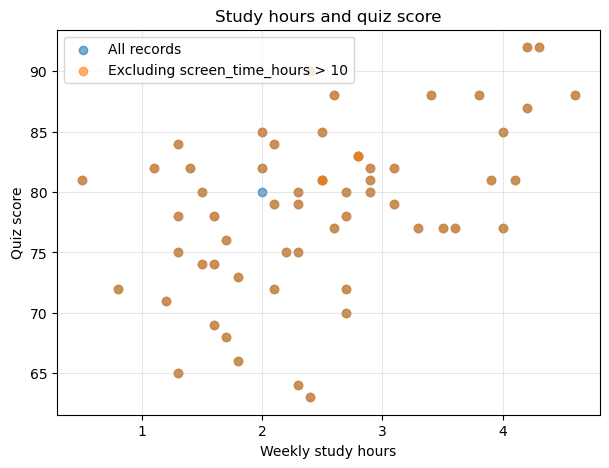

In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 實際欄位名稱：
# student_id, department, sleep_hours,
# screen_time_hours, study_hours, attendance_rate, quiz_score

# -----------------------------------------
# 0. 基本檢查
# -----------------------------------------
required_cols = [
    "department",
    "quiz_score",
    "study_hours",
    "screen_time_hours"
]

print("df 形狀：", df.shape)
print("df 欄位：", df.columns.tolist())

missing_cols = [c for c in required_cols if c not in df.columns]
if missing_cols:
    raise ValueError(f"df 缺少必要欄位：{missing_cols}")

# -----------------------------------------
# 1. 遺失值與描述統計
# -----------------------------------------
print("\n各欄位遺失值數量：")
print(df[required_cols].isna().sum())

print("\n數值欄位描述統計：")
print(df[["quiz_score", "study_hours", "screen_time_hours"]].describe())

# -----------------------------------------
# 2. 科系分組：筆數與平均
# -----------------------------------------
group_result = (
    df
    .groupby("department", dropna=False)
    .agg(
        筆數=("quiz_score", "size"),
        成績平均=("quiz_score", "mean"),
        讀書時數平均=("study_hours", "mean"),
        螢幕時間平均=("screen_time_hours", "mean"),
    )
    .round(2)
)

print("\n各科系筆數與平均：")
print(group_result)

# -----------------------------------------
# 3. 相關分析函式
# -----------------------------------------
def run_corr_analysis(data, label):
    # 只保留三個變數皆非缺失的資料，計算有效配對數
    valid = data[["study_hours", "screen_time_hours", "quiz_score"]].dropna()

    n_valid = len(valid)

    corr_study = valid["study_hours"].corr(valid["quiz_score"])
    corr_screen = valid["screen_time_hours"].corr(valid["quiz_score"])

    print(f"\n【{label}】")
    print(f"有效配對數：{n_valid}")
    print(f"study_hours 與 quiz_score 的 Pearson 相關：{corr_study:.3f}")
    print(f"screen_time_hours 與 quiz_score 的 Pearson 相關：{corr_screen:.3f}")

    return {
        "處理方式": label,
        "有效配對數": n_valid,
        "讀書時數與成績相關": corr_study,
        "螢幕時間與成績相關": corr_screen,
    }

# -----------------------------------------
# 4. 處理一：保留全部資料
# -----------------------------------------
result_keep = run_corr_analysis(
    df,
    "保留全部資料（含 screen_time_hours > 10）"
)

# -----------------------------------------
# 5. 處理二：排除螢幕時間 > 10
# -----------------------------------------
df_no_high_screen = df[df["screen_time_hours"] <= 10].copy()

print(f"\n排除 screen_time_hours > 10 後，剩餘資料筆數：{len(df_no_high_screen)}")
print(f"被排除的資料筆數：{len(df) - len(df_no_high_screen)}")

result_exclude = run_corr_analysis(
    df_no_high_screen,
    "排除 screen_time_hours > 10 的資料"
)

# -----------------------------------------
# 6. 兩種處理比較
# -----------------------------------------
comparison = pd.DataFrame([result_keep, result_exclude]).round(3)

print("\n兩種螢幕時間處理方式的比較：")
print(comparison)

# -----------------------------------------
# 7. 散佈圖
# -----------------------------------------
plt.figure(figsize=(7, 5))

plt.scatter(
    df["study_hours"],
    df["quiz_score"],
    alpha=0.6,
    label="All records"
)

plt.scatter(
    df_no_high_screen["study_hours"],
    df_no_high_screen["quiz_score"],
    alpha=0.6,
    label="Excluding screen_time_hours > 10"
)

plt.xlabel("Weekly study hours")
plt.ylabel("Quiz score")
plt.title("Study hours and quiz score")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

### ✍️ 小任務 MB｜結果與檢核（請雙擊填寫）
- 問題及使用的資料／欄位：使用的資料共有 60 筆，包含 7 個欄位：student_id、department、sleep_hours、screen_time_hours、study_hours、attendance_rate、quiz_score。
- 實際輸出與至少一項依據數字的觀察：
    - 各科系筆數與平均如下：  
企業管理有 21 筆，平均 quiz_score 為 80.67 分、
平均 study_hours 為 2.66 小時、平均 screen_time_hours 為 4.49 小時；  
資訊管理有 15 筆，平均 quiz_score 為 79.73 分、
平均 study_hours 為 2.42 小時、平均 screen_time_hours 為 5.08 小時；  
金融管理有 24 筆，平均 quiz_score 為 76.58 分、
平均 study_hours 為 2.34 小時、平均 screen_time_hours 為 5.27 小時。
    - 觀察：企業管理的平均成績最高（80.67 分），
金融管理最低（76.58 分）；企業管理的平均讀書時數最高（2.66 小時），
平均螢幕時間最低（4.49 小時）。
- 圖表或模型結果的解讀（依任務要求）：study_hours 與 quiz_score 的 Pearson 相關係數為 0.471，
顯示兩者呈中度正相關，即讀書時數較高的學生，
小考成績傾向較高。
screen_time_hours 與 quiz_score 的 Pearson 相關係數為 -0.364，
顯示兩者呈負相關，即螢幕時間較高的學生，
小考成績傾向較低。
- 資料品質、模擬資料或評估限制：分析結果只能描述變數間的關聯，不能推論因果。例如：  
study_hours 與 quiz_score 呈正相關，不代表增加讀書時間一定會提高成績。  
screen_time_hours 與 quiz_score 呈負相關，也不代表減少螢幕時間一定會提高成績。  
睡眠時數、出席率、先備能力、修課難度或其他未觀測因素，都可能同時影響學習行為與成績。  
screen_time_hours 的最大值為 15，代表資料中確實有超過 10 小時的高螢幕時間紀錄，但只有 1 筆，因此排除後的相關係數變化不應過度解讀。
- 驗證方法與結果：以散佈圖檢查 study_hours 與 quiz_score 的關係，
圖形大致呈現正相關趨勢，與相關係數 0.471 及 0.474 的方向一致。
- AI 工具、實際提示詞、人工修改與遇到的問題：perplexity。我是 Python 初學者，請協助我完成以下資料分析小任務：
請協助我規劃資料分析報告：包含分組人數和平均、有效配對、圖表與 15 小時紀錄的兩種處理比較。保留 df、不要憑空填寫結果，並指出因果推論限制。
請拆成小步驟，提供繁體中文教學註解、預期輸出應如何檢查，並提醒不能從這份模擬資料推論因果。  
  將AI 原本假設的中文欄位名稱（科系、成績、讀書時數、螢幕時間）改為實際欄位名稱 department、quiz_score、study_hours、screen_time_hours。
- 重新執行是否成功及環境或檔案需求：重新執行成功
